
# FD004 DS-A: Held-Out Operating-Regime Shift

## Objective
Evaluate the robustness of the frozen FD004 prognostics and uncertainty pipeline when one operating regime is completely excluded from model training and conformal calibration.

### DS-A rule
- Train: engines/data from non-held-out regimes
- Calibration: non-held-out regimes only
- Test: held-out operating regime
- No model retuning based on DS-A test performance

### Baseline configuration
- Dataset: NASA C-MAPSS FD004
- Operating settings: setting_1, setting_2, setting_3
- Number of regimes: 6
- RUL clipping: 125 cycles
- Window length: 30 cycles
- Selected sensors: 14
- Random seed: 42


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Imports and constants

In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

DATA_DIR = "/content/drive/MyDrive/CMAPSSData"

RUL_CLIP = 125
WINDOW_SIZE = 30
N_REGIMES = 6

OPERATING_SETTINGS = [
    "setting_1",
    "setting_2",
    "setting_3"
]

SELECTED_SENSORS = [
    "s_2", "s_3", "s_4", "s_7", "s_8", "s_9",
    "s_11", "s_12", "s_13", "s_14",
    "s_15", "s_17", "s_20", "s_21"
]

ALL_RAW_COLS = (
    ["unit_id", "time_cycles"]
    + OPERATING_SETTINGS
    + [f"s_{i}" for i in range(1, 22)]
)

print("DS-A configuration loaded.")
print(f"Seed: {SEED}")
print(f"Number of regimes: {N_REGIMES}")
print(f"Window size: {WINDOW_SIZE}")


DS-A configuration loaded.
Seed: 42
Number of regimes: 6
Window size: 30


##Load raw FD004 training data


In [3]:

train_path = os.path.join(DATA_DIR, "train_FD004.txt")

train_raw = pd.read_csv(
    train_path,
    sep=r"\s+",
    header=None
)

# C-MAPSS files may contain trailing empty columns
train_raw = train_raw.iloc[:, :len(ALL_RAW_COLS)]
train_raw.columns = ALL_RAW_COLS

print("FD004 training data loaded.")
print("Shape:", train_raw.shape)
print("Number of engines:", train_raw["unit_id"].nunique())

display(train_raw.head())


FD004 training data loaded.
Shape: (61249, 26)
Number of engines: 249


,unit_id,time_cycles,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
0,1,1,42.0049,0.8400,100.0,445.00,549.68,1343.43,1112.93,3.91,...,129.78,2387.99,8074.83,9.3335,0.02,330,2212,100.00,10.62,6.3670
1,1,2,20.0020,0.7002,100.0,491.19,606.07,1477.61,1237.50,9.35,...,312.59,2387.73,8046.13,9.1913,0.02,361,2324,100.00,24.37,14.6552
2,1,3,42.0038,0.8409,100.0,445.00,548.95,1343.12,1117.05,3.91,...,129.62,2387.97,8066.62,9.4007,0.02,329,2212,100.00,10.48,6.4213
3,1,4,42.0000,0.8400,100.0,445.00,548.70,1341.24,1118.03,3.91,...,129.80,2388.02,8076.05,9.3369,0.02,328,2212,100.00,10.54,6.4176
4,1,5,25.0063,0.6207,60.0,462.54,536.10,1255.23,1033.59,7.05,...,164.11,2028.08,7865.80,10.8366,0.02,305,1915,84.93,14.03,8.6754


## Calculate training RUL

In [4]:
max_cycles = (
    train_raw.groupby("unit_id")["time_cycles"]
    .max()
    .rename("max_cycle")
)

train_raw = train_raw.merge(
    max_cycles,
    on="unit_id",
    how="left"
)

train_raw["RUL_raw"] = (
    train_raw["max_cycle"] - train_raw["time_cycles"]
)

train_raw["RUL"] = train_raw["RUL_raw"].clip(
    upper=RUL_CLIP
)

print(train_raw[
    ["unit_id", "time_cycles", "RUL_raw", "RUL"]
].head(10))


   unit_id  time_cycles  RUL_raw  RUL
0        1            1      320  125
1        1            2      319  125
2        1            3      318  125
3        1            4      317  125
4        1            5      316  125
5        1            6      315  125
6        1            7      314  125
7        1            8      313  125
8        1            9      312  125
9        1           10      311  125


## Fit the six operating regimes


In [5]:
setting_scaler = StandardScaler()

settings_scaled = setting_scaler.fit_transform(
    train_raw[OPERATING_SETTINGS]
)

kmeans = KMeans(
    n_clusters=N_REGIMES,
    random_state=SEED,
    n_init=10
)

train_raw["regime"] = kmeans.fit_predict(
    settings_scaled
)

print("Operating regimes assigned.")
print(
    train_raw["regime"]
    .value_counts()
    .sort_index()
)


Operating regimes assigned.
regime
0    15395
1     9224
2     9139
3     9091
4     9238
5     9162
Name: count, dtype: int64


## Create the regime summary

In [6]:
regime_summary = (
    train_raw
    .groupby("regime")
    .agg(
        observations=("unit_id", "size"),
        engines=("unit_id", "nunique"),
        mean_RUL=("RUL", "mean"),
        median_RUL=("RUL", "median"),
        mean_setting_1=("setting_1", "mean"),
        mean_setting_2=("setting_2", "mean"),
        mean_setting_3=("setting_3", "mean")
    )
    .reset_index()
)

regime_summary["observation_pct"] = (
    100
    * regime_summary["observations"]
    / len(train_raw)
)

display(
    regime_summary.round(3)
)


,regime,observations,engines,mean_RUL,median_RUL,mean_setting_1,mean_setting_2,mean_setting_3,observation_pct
0,0,15395,249,92.759,123.0,42.003,0.840,100.0,25.135
1,1,9224,249,93.098,123.0,10.003,0.251,100.0,15.060
2,2,9139,249,93.273,122.0,25.003,0.621,60.0,14.921
3,3,9091,249,93.099,123.0,20.003,0.701,100.0,14.843
4,4,9238,249,92.744,121.0,0.002,0.000,100.0,15.083
5,5,9162,249,93.095,122.0,35.003,0.841,100.0,14.959


## Determine engine/regime overlap


In [7]:
engine_regime_counts = (
    train_raw
    .groupby("unit_id")["regime"]
    .nunique()
)

print("Regimes encountered per engine:")
display(
    engine_regime_counts
    .value_counts()
    .sort_index()
    .rename_axis("number_of_regimes")
    .reset_index(name="number_of_engines")
)

print(
    "\nMedian regimes per engine:",
    engine_regime_counts.median()
)

print(
    "Maximum regimes per engine:",
    engine_regime_counts.max()
)


Regimes encountered per engine:


,number_of_regimes,number_of_engines
0,6,249



Median regimes per engine: 6.0
Maximum regimes per engine: 6


## Set held-out regime


In [8]:
HELD_OUT_REGIME = 0

print(f"DS-A held-out operating regime: {HELD_OUT_REGIME}")

heldout_rows = train_raw[
    train_raw["regime"] == HELD_OUT_REGIME
]

print("Held-out observations:", len(heldout_rows))
print(
    "Percentage of dataset:",
    round(100 * len(heldout_rows) / len(train_raw), 2),
    "%"
)
print(
    "Engines represented:",
    heldout_rows["unit_id"].nunique()
)


DS-A held-out operating regime: 0
Held-out observations: 15395
Percentage of dataset: 25.14 %
Engines represented: 249


## Create engine-level split

In [9]:
from sklearn.model_selection import train_test_split

all_engines = np.array(
    sorted(train_raw["unit_id"].unique())
)

train_engines, temp_engines = train_test_split(
    all_engines,
    test_size=0.30,
    random_state=SEED
)

cal_engines, test_engines = train_test_split(
    temp_engines,
    test_size=0.50,
    random_state=SEED
)

print("Train engines:", len(train_engines))
print("Calibration engines:", len(cal_engines))
print("Test engines:", len(test_engines))

print(
    "\nTotal:",
    len(train_engines)
    + len(cal_engines)
    + len(test_engines)
)


Train engines: 174
Calibration engines: 37
Test engines: 38

Total: 249


## Verify zero engine leakage

In [10]:
assert len(
    set(train_engines) & set(cal_engines)
) == 0

assert len(
    set(train_engines) & set(test_engines)
) == 0

assert len(
    set(cal_engines) & set(test_engines)
) == 0

print("✓ No engine leakage between splits.")


✓ No engine leakage between splits.


## Apply the DS-A regime exclusion

In [11]:
train_ds = train_raw[
    train_raw["unit_id"].isin(train_engines)
].copy()

cal_ds = train_raw[
    train_raw["unit_id"].isin(cal_engines)
].copy()

test_ds = train_raw[
    train_raw["unit_id"].isin(test_engines)
].copy()


# Remove held-out regime from TRAIN
train_ds = train_ds[
    train_ds["regime"] != HELD_OUT_REGIME
].copy()

# Remove held-out regime from CALIBRATION
cal_ds = cal_ds[
    cal_ds["regime"] != HELD_OUT_REGIME
].copy()

# TEST contains only held-out regime observations
test_ds = test_ds[
    test_ds["regime"] == HELD_OUT_REGIME
].copy()


In [12]:
print("TRAIN")
print(train_ds["regime"].value_counts().sort_index())

print("\nCALIBRATION")
print(cal_ds["regime"].value_counts().sort_index())

print("\nTEST")
print(test_ds["regime"].value_counts().sort_index())


TRAIN
regime
1    6409
2    6378
3    6354
4    6491
5    6438
Name: count, dtype: int64

CALIBRATION
regime
1    1385
2    1401
3    1339
4    1347
5    1351
Name: count, dtype: int64

TEST
regime
0    2352
Name: count, dtype: int64


## Hard validation

In [13]:
assert HELD_OUT_REGIME not in train_ds["regime"].unique()
assert HELD_OUT_REGIME not in cal_ds["regime"].unique()

assert set(
    test_ds["regime"].unique()
) == {HELD_OUT_REGIME}

assert set(
    train_ds["unit_id"].unique()
).isdisjoint(
    set(test_ds["unit_id"].unique())
)

assert set(
    cal_ds["unit_id"].unique()
).isdisjoint(
    set(test_ds["unit_id"].unique())
)

print("✓ DS-A split validation passed.")
print("✓ Held-out regime absent from training.")
print("✓ Held-out regime absent from calibration.")
print("✓ Test contains held-out regime only.")
print("✓ Engine-level isolation preserved.")


✓ DS-A split validation passed.
✓ Held-out regime absent from training.
✓ Held-out regime absent from calibration.
✓ Test contains held-out regime only.
✓ Engine-level isolation preserved.


## Fit sensor scaling on eligible training observations only

In [14]:
# ============================================================
# DS-A preprocessing
# Fit sensor scaler using TRAIN ENGINES and NON-HELD-OUT
# endpoint-eligible operating conditions only
# ============================================================

sensor_scaler = StandardScaler()

scaler_fit_df = train_raw[
    (train_raw["unit_id"].isin(train_engines)) &
    (train_raw["regime"] != HELD_OUT_REGIME)
].copy()

sensor_scaler.fit(
    scaler_fit_df[SELECTED_SENSORS]
)

print("Sensor scaler fitted.")
print("Rows used:", len(scaler_fit_df))
print("Engines used:", scaler_fit_df["unit_id"].nunique())


Sensor scaler fitted.
Rows used: 32070
Engines used: 174


## Scale the original trajectories

In [15]:
# Keep complete trajectories intact.
# Only the sensor values are transformed.

trajectory_df = train_raw.copy()

trajectory_df[SELECTED_SENSORS] = sensor_scaler.transform(
    trajectory_df[SELECTED_SENSORS]
)

trajectory_df = trajectory_df.sort_values(
    ["unit_id", "time_cycles"]
).reset_index(drop=True)

print("Full trajectories prepared:", trajectory_df.shape)


Full trajectories prepared: (61249, 30)


## Leakage-safe window function

In [16]:
def create_ds_a_windows(
    df,
    engine_ids,
    endpoint_mode,
    held_out_regime=0,
    window_size=30
):
    """
    Build windows from uninterrupted original engine trajectories.

    endpoint_mode:
        'seen'    -> endpoint regime must NOT be held out
        'heldout' -> endpoint regime MUST be held out

    Returns
    -------
    X_sensors : (N, window_size, 14)
    X_regimes : (N, window_size)
    y         : (N,)
    ids       : (N,)
    cycles    : endpoint cycle for each window
    endpoint_regimes : regime at prediction endpoint
    """

    X_sensors = []
    X_regimes = []
    y = []
    ids = []
    cycles = []
    endpoint_regimes = []

    for engine_id in sorted(engine_ids):

        eng = (
            df[df["unit_id"] == engine_id]
            .sort_values("time_cycles")
            .reset_index(drop=True)
        )

        if len(eng) < window_size:
            continue

        for end_idx in range(window_size - 1, len(eng)):

            start_idx = end_idx - window_size + 1

            window = eng.iloc[start_idx:end_idx + 1]

            endpoint_regime = int(
                eng.iloc[end_idx]["regime"]
            )

            # Eligibility depends ONLY on prediction endpoint
            if endpoint_mode == "seen":
                if endpoint_regime == held_out_regime:
                    continue

            elif endpoint_mode == "heldout":
                if endpoint_regime != held_out_regime:
                    continue

            else:
                raise ValueError(
                    "endpoint_mode must be 'seen' or 'heldout'"
                )

            # Ensure cycles are genuinely consecutive
            cycle_values = window["time_cycles"].to_numpy()

            if not np.all(np.diff(cycle_values) == 1):
                raise ValueError(
                    f"Non-consecutive window detected "
                    f"for engine {engine_id}"
                )

            X_sensors.append(
                window[SELECTED_SENSORS].to_numpy(
                    dtype=np.float32
                )
            )

            X_regimes.append(
                window["regime"].to_numpy(
                    dtype=np.int32
                )
            )

            y.append(
                float(eng.iloc[end_idx]["RUL"])
            )

            ids.append(engine_id)

            cycles.append(
                int(eng.iloc[end_idx]["time_cycles"])
            )

            endpoint_regimes.append(
                endpoint_regime
            )

    return (
        np.asarray(X_sensors, dtype=np.float32),
        np.asarray(X_regimes, dtype=np.int32),
        np.asarray(y, dtype=np.float32),
        np.asarray(ids, dtype=np.int32),
        np.asarray(cycles, dtype=np.int32),
        np.asarray(endpoint_regimes, dtype=np.int32)
    )


## Construct train, calibration and DS-A test windows

In [17]:
(
    X_train_sensors,
    reg_train,
    y_train_ds,
    ids_train,
    cycles_train,
    reg_train_endpoint
) = create_ds_a_windows(
    trajectory_df,
    train_engines,
    endpoint_mode="seen",
    held_out_regime=HELD_OUT_REGIME,
    window_size=WINDOW_SIZE
)


(
    X_cal_sensors,
    reg_cal,
    y_cal_ds,
    ids_cal,
    cycles_cal,
    reg_cal_endpoint
) = create_ds_a_windows(
    trajectory_df,
    cal_engines,
    endpoint_mode="seen",
    held_out_regime=HELD_OUT_REGIME,
    window_size=WINDOW_SIZE
)


(
    X_test_sensors,
    reg_test,
    y_test_ds,
    ids_test,
    cycles_test,
    reg_test_endpoint
) = create_ds_a_windows(
    trajectory_df,
    test_engines,
    endpoint_mode="heldout",
    held_out_regime=HELD_OUT_REGIME,
    window_size=WINDOW_SIZE
)


print("TRAIN:", X_train_sensors.shape, y_train_ds.shape)
print("CAL  :", X_cal_sensors.shape, y_cal_ds.shape)
print("TEST :", X_test_sensors.shape, y_test_ds.shape)


TRAIN: (28322, 30, 14) (28322,)
CAL  : (6021, 30, 14) (6021,)
TEST : (2043, 30, 14) (2043,)


## Validate the windows

In [18]:
print("Train endpoint regimes:",
      np.unique(reg_train_endpoint))

print("Calibration endpoint regimes:",
      np.unique(reg_cal_endpoint))

print("Test endpoint regimes:",
      np.unique(reg_test_endpoint))


assert HELD_OUT_REGIME not in np.unique(
    reg_train_endpoint
)

assert HELD_OUT_REGIME not in np.unique(
    reg_cal_endpoint
)

assert set(
    np.unique(reg_test_endpoint)
) == {HELD_OUT_REGIME}


assert set(ids_train).isdisjoint(
    set(ids_cal)
)

assert set(ids_train).isdisjoint(
    set(ids_test)
)

assert set(ids_cal).isdisjoint(
    set(ids_test)
)

assert X_train_sensors.shape[1] == WINDOW_SIZE
assert X_cal_sensors.shape[1] == WINDOW_SIZE
assert X_test_sensors.shape[1] == WINDOW_SIZE

print("\n✓ Window construction passed.")
print("✓ No engine leakage.")
print("✓ Train/cal endpoints exclude held-out regime.")
print("✓ Test endpoints contain held-out regime only.")
print("✓ Every sequence contains 30 consecutive cycles.")


Train endpoint regimes: [1 2 3 4 5]
Calibration endpoint regimes: [1 2 3 4 5]
Test endpoint regimes: [0]

✓ Window construction passed.
✓ No engine leakage.
✓ Train/cal endpoints exclude held-out regime.
✓ Test endpoints contain held-out regime only.
✓ Every sequence contains 30 consecutive cycles.


In [19]:
import tensorflow as tf

reg_train_oh = tf.keras.utils.to_categorical(
    reg_train,
    num_classes=N_REGIMES
)

reg_cal_oh = tf.keras.utils.to_categorical(
    reg_cal,
    num_classes=N_REGIMES
)

reg_test_oh = tf.keras.utils.to_categorical(
    reg_test,
    num_classes=N_REGIMES
)

X_train_ds = np.concatenate(
    [X_train_sensors, reg_train_oh],
    axis=-1
)

X_cal_ds = np.concatenate(
    [X_cal_sensors, reg_cal_oh],
    axis=-1
)

X_test_ds = np.concatenate(
    [X_test_sensors, reg_test_oh],
    axis=-1
)

print("Final model inputs:")
print("Train:", X_train_ds.shape)
print("Cal  :", X_cal_ds.shape)
print("Test :", X_test_ds.shape)

assert X_train_ds.shape[-1] == 20

print("✓ 14 sensor channels + 6 regime channels = 20 features.")


Final model inputs:
Train: (28322, 30, 20)
Cal  : (6021, 30, 20)
Test : (2043, 30, 20)
✓ 14 sensor channels + 6 regime channels = 20 features.


## Fixed experiment settings

In [20]:
import os
import random
import numpy as np
import tensorflow as tf

from tensorflow.keras.layers import Input, Dense, LSTM, Bidirectional, Layer
from tensorflow.keras.models import Model

SEED = 42
ALPHA = 0.20
QUANTILES = [0.10, 0.50, 0.90]

EPOCHS = 25
BATCH_SIZE = 256

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(SEED)

print("DS-A model configuration")
print("Seed:", SEED)
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Target coverage:", 100 * (1 - ALPHA), "%")

DS-A model configuration
Seed: 42
Epochs: 25
Batch size: 256
Target coverage: 80.0 %


## Frozen temporal-attention architecture

In [21]:

class FastTemporalAttention(Layer):

    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def build(self, input_shape):

        dim = input_shape[-1]

        self.W = self.add_weight(
            name="W",
            shape=(dim, dim),
            initializer="glorot_uniform",
            trainable=True
        )

        self.b = self.add_weight(
            name="b",
            shape=(dim,),
            initializer="zeros",
            trainable=True
        )

        self.v = self.add_weight(
            name="v",
            shape=(dim, 1),
            initializer="glorot_uniform",
            trainable=True
        )

        super().build(input_shape)

    def call(self, inputs):

        e = tf.nn.tanh(
            tf.tensordot(inputs, self.W, axes=1)
            + self.b
        )

        scores = tf.tensordot(
            e,
            self.v,
            axes=1
        )

        weights = tf.nn.softmax(
            scores,
            axis=1
        )

        return tf.reduce_sum(
            inputs * weights,
            axis=1
        )

## Quantile loss

In [22]:
def tilted_loss(q, y_true, y_pred):

    error = y_true - y_pred

    return tf.maximum(
        q * error,
        (q - 1.0) * error
    )


def multi_quantile_pinball_loss(
    y_true,
    y_pred
):

    y_true = tf.cast(
        tf.reshape(y_true, (-1, 1)),
        tf.float32
    )

    losses = []

    for i, q in enumerate(QUANTILES):

        losses.append(
            tilted_loss(
                q,
                y_true,
                y_pred[:, i:i+1]
            )
        )

    return tf.reduce_mean(
        tf.add_n(losses)
    )


## Build the frozen Paper 1 model

In [23]:
def build_ds_a_model():

    inputs = Input(
        shape=(WINDOW_SIZE, 20),
        name="input_window"
    )

    # Same 20D -> 18D projection used in final Paper 1 model
    projection = Dense(
        18,
        use_bias=False,
        name="projection"
    )(inputs)

    lstm_output = Bidirectional(
        LSTM(
            64,
            return_sequences=True
        ),
        name="bilstm"
    )(projection)

    context = FastTemporalAttention(
        name="temporal_attention"
    )(lstm_output)

    outputs = Dense(
        3,
        activation="linear",
        name="quantiles"
    )(context)

    model = Model(
        inputs=inputs,
        outputs=outputs,
        name="FD004_DS_A_B6"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=1e-3
        ),
        loss=multi_quantile_pinball_loss
    )

    return model


model = build_ds_a_model()

model.summary()

Model: "FD004_DS_A_B6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_window (InputLayer)       │ (None, 30, 20)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ projection (Dense)              │ (None, 30, 18)         │           360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm (Bidirectional)          │ (None, 30, 128)        │        42,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ temporal_attention              │ (None, 128)            │        16,640 │
│ (FastTemporalAttention)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ quantiles (Dense)               │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,883 (233.92 KB)

 Trainable params: 59,883 (233.92 KB)

 Non-trainable params: 0 (0.00 B)

## Train the model

In [24]:
set_seed(SEED)

history = model.fit(
    X_train_ds,
    y_train_ds,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=2,
    shuffle=True
)


Epoch 1/25
111/111 - 7s - 64ms/step - loss: 114.8550
Epoch 2/25
111/111 - 1s - 10ms/step - loss: 91.3946
Epoch 3/25
111/111 - 2s - 14ms/step - loss: 76.5766
Epoch 4/25
111/111 - 2s - 21ms/step - loss: 64.7461
Epoch 5/25
111/111 - 1s - 10ms/step - loss: 55.1087
Epoch 6/25
111/111 - 1s - 9ms/step - loss: 47.2368
Epoch 7/25
111/111 - 1s - 12ms/step - loss: 40.8947
Epoch 8/25
111/111 - 1s - 10ms/step - loss: 35.7775
Epoch 9/25
111/111 - 1s - 10ms/step - loss: 31.7280
Epoch 10/25
111/111 - 1s - 10ms/step - loss: 29.2791
Epoch 11/25
111/111 - 1s - 11ms/step - loss: 29.0245
Epoch 12/25
111/111 - 1s - 10ms/step - loss: 28.9571
Epoch 13/25
111/111 - 1s - 13ms/step - loss: 28.9148
Epoch 14/25
111/111 - 2s - 14ms/step - loss: 28.8926
Epoch 15/25
111/111 - 1s - 13ms/step - loss: 28.8712
Epoch 16/25
111/111 - 1s - 10ms/step - loss: 28.8845
Epoch 17/25
111/111 - 1s - 10ms/step - loss: 28.8650
Epoch 18/25
111/111 - 1s - 11ms/step - loss: 28.6278
Epoch 19/25
111/111 - 1s - 10ms/step - loss: 26.2917
Ep

## Generate calibration and held-out predictions

In [25]:
cal_predictions = model.predict(
    X_cal_ds,
    batch_size=512,
    verbose=0
)

test_predictions = model.predict(
    X_test_ds,
    batch_size=512,
    verbose=0
)

print(
    "Calibration predictions:",
    cal_predictions.shape
)

print(
    "DS-A predictions:",
    test_predictions.shape
)


p10_cal_raw = cal_predictions[:, 0]
p50_cal = cal_predictions[:, 1]
p90_cal_raw = cal_predictions[:, 2]

p10_test_raw = test_predictions[:, 0]
p50_test = test_predictions[:, 1]
p90_test_raw = test_predictions[:, 2]


Calibration predictions: (6021, 3)
DS-A predictions: (2043, 3)


## First point-prediction result

In [26]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test_ds,
        p50_test
    )
)

test_mae = mean_absolute_error(
    y_test_ds,
    p50_test
)

print("=" * 60)
print("DS-A POINT PREDICTION")
print("=" * 60)

print(f"RMSE : {test_rmse:.3f}")
print(f"MAE  : {test_mae:.3f}")
print(f"Test windows : {len(y_test_ds)}")
print(
    "Test engines :",
    len(np.unique(ids_test))
)


DS-A POINT PREDICTION
RMSE : 38.668
MAE  : 28.089
Test windows : 2043
Test engines : 38


# Asymmetric CQR
##Conformal quantile helper


In [27]:
def conformal_quantile(
    scores,
    alpha
):

    scores = np.asarray(scores)

    n = len(scores)

    q_level = np.ceil(
        (n + 1) * (1 - alpha)
    ) / n

    q_level = min(
        1.0,
        q_level
    )

    return float(
        np.quantile(
            scores,
            q_level,
            method="higher"
        )
    )


## Asymmetric CQR calibration

In [28]:
lower_scores = (
    p10_cal_raw - y_cal_ds
)

upper_scores = (
    y_cal_ds - p90_cal_raw
)

q_hat_lower = conformal_quantile(
    lower_scores,
    ALPHA / 2
)

q_hat_upper = conformal_quantile(
    upper_scores,
    ALPHA / 2
)

print(
    "Asymmetric CQR corrections:"
)

print(
    f"Q lower = {q_hat_lower:.3f}"
)

print(
    f"Q upper = {q_hat_upper:.3f}"
)

Asymmetric CQR corrections:
Q lower = 1.169
Q upper = -0.302


##  Apply Asymmetric CQR to DS-A

In [29]:
asym_lower = np.maximum(
    0.0,
    p10_test_raw - q_hat_lower
)

asym_upper = np.maximum(
    0.0,
    p90_test_raw + q_hat_upper
)

asym_covered = (
    (y_test_ds >= asym_lower) &
    (y_test_ds <= asym_upper)
)

asym_picp = (
    100 * asym_covered.mean()
)

asym_mpiw = np.mean(
    asym_upper - asym_lower
)

print("=" * 60)
print("DS-A ASYMMETRIC CQR")
print("=" * 60)

print(
    f"Coverage : {asym_picp:.2f}%"
)

print(
    f"Mean width: {asym_mpiw:.3f}"
)

print(
    f"Target    : {100*(1-ALPHA):.1f}%"
)


DS-A ASYMMETRIC CQR
Coverage : 72.15%
Mean width: 85.166
Target    : 80.0%


#  Balanced Engine CQR
## Calibration error by engine

In [30]:
cal_errors = np.maximum(
    p10_cal_raw - y_cal_ds,
    y_cal_ds - p90_cal_raw
)

calibration_engines = np.unique(
    ids_cal
)

engine_q80_errors = []

for eng in calibration_engines:

    mask = ids_cal == eng

    engine_q80_errors.append(
        np.quantile(
            cal_errors[mask],
            0.80
        )
    )

engine_q80_errors = np.asarray(
    engine_q80_errors
)

print(
    "Calibration engines:",
    len(calibration_engines)
)

print(
    "Engine q80 values:",
    engine_q80_errors.shape
)


Calibration engines: 37
Engine q80 values: (37,)


## Balanced Engine correction

In [31]:
n_eng = len(
    calibration_engines
)

q_level_engine = np.ceil(
    (n_eng + 1) *
    (1 - ALPHA)
) / n_eng

q_level_engine = min(
    1.0,
    q_level_engine
)

q_hat_balanced = float(
    np.quantile(
        engine_q80_errors,
        q_level_engine,
        method="higher"
    )
)

print(
    f"Balanced Engine Q_hat = "
    f"{q_hat_balanced:.3f}"
)


Balanced Engine Q_hat = 4.090


## Apply Balanced Engine CQR

In [32]:
balanced_lower = np.maximum(
    0.0,
    p10_test_raw - q_hat_balanced
)

balanced_upper = np.maximum(
    0.0,
    p90_test_raw + q_hat_balanced
)

balanced_covered = (
    (y_test_ds >= balanced_lower) &
    (y_test_ds <= balanced_upper)
)

balanced_picp = (
    100 * balanced_covered.mean()
)

balanced_mpiw = np.mean(
    balanced_upper -
    balanced_lower
)

print("=" * 60)
print("DS-A BALANCED ENGINE CQR")
print("=" * 60)

print(
    f"Coverage  : "
    f"{balanced_picp:.2f}%"
)

print(
    f"Mean width: "
    f"{balanced_mpiw:.3f}"
)

print(
    f"Q_hat     : "
    f"{q_hat_balanced:.3f}"
)


DS-A BALANCED ENGINE CQR
Coverage  : 87.57%
Mean width: 92.479
Q_hat     : 4.090


## First DS-A comparison table

In [33]:
ds_a_summary = pd.DataFrame([
    {
        "Method":
            "Asymmetric CQR",

        "RMSE":
            test_rmse,

        "MAE":
            test_mae,

        "Coverage":
            asym_picp,

        "Mean_Width":
            asym_mpiw,
    },

    {
        "Method":
            "Balanced Engine CQR",

        "RMSE":
            test_rmse,

        "MAE":
            test_mae,

        "Coverage":
            balanced_picp,

        "Mean_Width":
            balanced_mpiw,
    }
])

display(
    ds_a_summary.round(3)
)


,Method,RMSE,MAE,Coverage,Mean_Width
0,Asymmetric CQR,38.668,28.089,72.149,85.166000
1,Balanced Engine CQR,38.668,28.089,87.567,92.478996


In [34]:
# ============================================================
# DS-A PER-ENGINE RELIABILITY
# ============================================================

engine_results = []

for eng in np.unique(ids_test):

    mask = ids_test == eng

    n_windows = np.sum(mask)

    asym_engine_coverage = (
        100 * np.mean(asym_covered[mask])
    )

    balanced_engine_coverage = (
        100 * np.mean(balanced_covered[mask])
    )

    asym_engine_width = np.mean(
        asym_upper[mask] -
        asym_lower[mask]
    )

    balanced_engine_width = np.mean(
        balanced_upper[mask] -
        balanced_lower[mask]
    )

    engine_rmse = np.sqrt(
        mean_squared_error(
            y_test_ds[mask],
            p50_test[mask]
        )
    )

    engine_mae = mean_absolute_error(
        y_test_ds[mask],
        p50_test[mask]
    )

    engine_results.append({
        "engine_id": int(eng),
        "n_windows": int(n_windows),

        "RMSE": engine_rmse,
        "MAE": engine_mae,

        "Asym_Coverage":
            asym_engine_coverage,

        "Asym_Width":
            asym_engine_width,

        "Balanced_Coverage":
            balanced_engine_coverage,

        "Balanced_Width":
            balanced_engine_width
    })


engine_results = pd.DataFrame(
    engine_results
)

display(
    engine_results
    .sort_values("Balanced_Coverage")
    .round(3)
)

,engine_id,n_windows,RMSE,MAE,Asym_Coverage,Asym_Width,Balanced_Coverage,Balanced_Width
13,115,27,76.667,71.194,55.556,90.213997,59.259,97.526001
0,17,25,69.170,59.812,64.000,90.200996,68.000,97.514000
21,156,26,68.099,60.334,61.538,90.226997,69.231,97.539001
1,25,27,61.174,53.819,70.370,89.494003,70.370,96.806000
31,201,83,20.017,16.247,22.892,79.123001,71.084,86.434998
29,194,29,64.331,57.059,68.966,89.681999,72.414,96.995003
26,181,30,63.432,55.347,73.333,89.915001,73.333,97.227997
19,138,48,56.958,46.062,66.667,89.472000,75.000,96.785004
16,120,32,58.296,46.381,68.750,89.981003,75.000,97.292999
36,240,32,62.967,51.758,71.875,90.111000,75.000,97.422997


In [35]:
TARGET = 80.0

engine_summary = pd.DataFrame({
    "Metric": [
        "Number of test engines",
        "Asymmetric engines >= target",
        "Balanced engines >= target",
        "Asymmetric worst-engine coverage",
        "Balanced worst-engine coverage",
        "Asymmetric median engine coverage",
        "Balanced median engine coverage"
    ],

    "Value": [
        len(engine_results),

        np.sum(
            engine_results["Asym_Coverage"]
            >= TARGET
        ),

        np.sum(
            engine_results["Balanced_Coverage"]
            >= TARGET
        ),

        engine_results[
            "Asym_Coverage"
        ].min(),

        engine_results[
            "Balanced_Coverage"
        ].min(),

        engine_results[
            "Asym_Coverage"
        ].median(),

        engine_results[
            "Balanced_Coverage"
        ].median()
    ]
})

display(engine_summary.round(3))

,Metric,Value
0,Number of test engines,38.000
1,Asymmetric engines >= target,13.000
2,Balanced engines >= target,24.000
3,Asymmetric worst-engine coverage,22.892
4,Balanced worst-engine coverage,59.259
5,Asymmetric median engine coverage,72.604
6,Balanced median engine coverage,86.617


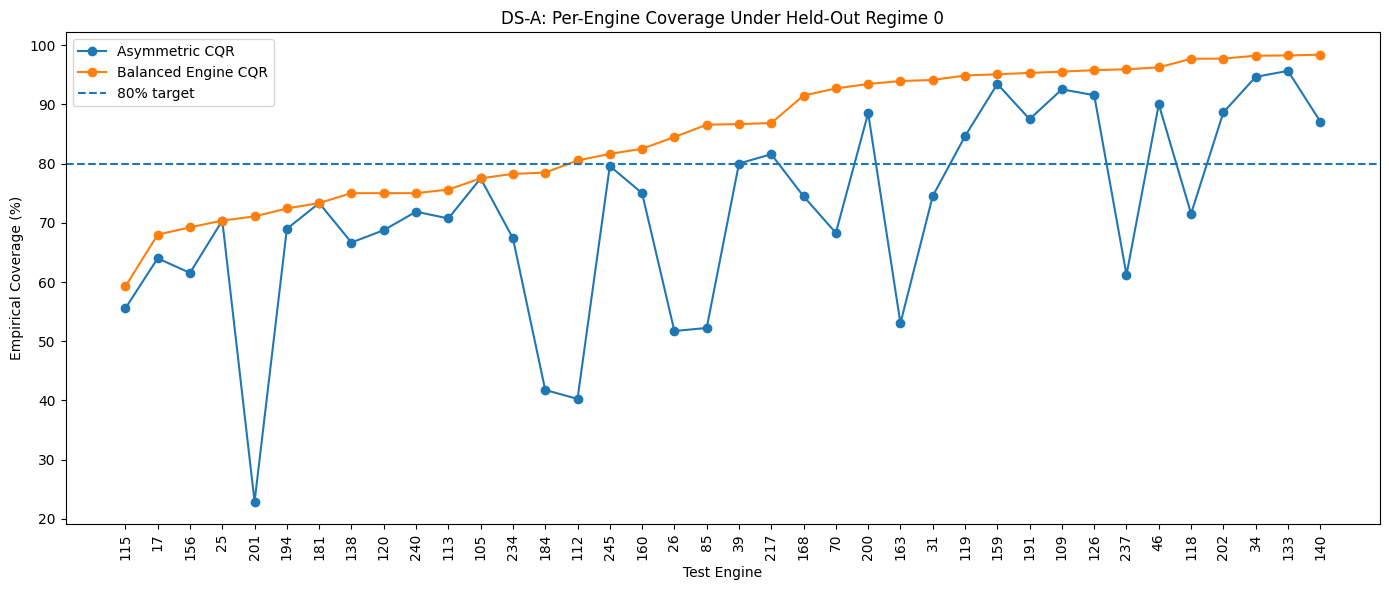

In [36]:
plot_df = (
    engine_results
    .sort_values("Balanced_Coverage")
    .reset_index(drop=True)
)

x = np.arange(len(plot_df))

plt.figure(figsize=(14, 6))

plt.plot(
    x,
    plot_df["Asym_Coverage"],
    marker="o",
    label="Asymmetric CQR"
)

plt.plot(
    x,
    plot_df["Balanced_Coverage"],
    marker="o",
    label="Balanced Engine CQR"
)

plt.axhline(
    80,
    linestyle="--",
    label="80% target"
)

plt.xticks(
    x,
    plot_df["engine_id"],
    rotation=90
)

plt.xlabel("Test Engine")
plt.ylabel("Empirical Coverage (%)")

plt.title(
    "DS-A: Per-Engine Coverage Under Held-Out Regime 0"
)

plt.legend()
plt.tight_layout()
plt.show()

In [37]:
# ============================================================
# DS-A: RELATIONSHIP BETWEEN POINT ERROR AND COVERAGE
# ============================================================

problem_engines = (
    engine_results[
        engine_results["Balanced_Coverage"] < 80
    ]
    .sort_values("Balanced_Coverage")
    .copy()
)

print("Problem engines:", len(problem_engines))

display(
    problem_engines[
        [
            "engine_id",
            "n_windows",
            "RMSE",
            "MAE",
            "Asym_Coverage",
            "Balanced_Coverage",
            "Balanced_Width"
        ]
    ].round(3)
)


Problem engines: 14


,engine_id,n_windows,RMSE,MAE,Asym_Coverage,Balanced_Coverage,Balanced_Width
13,115,27,76.667,71.194,55.556,59.259,97.526001
0,17,25,69.170,59.812,64.000,68.000,97.514000
21,156,26,68.099,60.334,61.538,69.231,97.539001
1,25,27,61.174,53.819,70.370,70.370,96.806000
31,201,83,20.017,16.247,22.892,71.084,86.434998
29,194,29,64.331,57.059,68.966,72.414,96.995003
26,181,30,63.432,55.347,73.333,73.333,97.227997
16,120,32,58.296,46.381,68.750,75.000,97.292999
19,138,48,56.958,46.062,66.667,75.000,96.785004
36,240,32,62.967,51.758,71.875,75.000,97.422997


In [38]:
rmse_cov_corr = engine_results[
    ["RMSE", "Balanced_Coverage"]
].corr().iloc[0, 1]

mae_cov_corr = engine_results[
    ["MAE", "Balanced_Coverage"]
].corr().iloc[0, 1]

print(
    f"RMSE vs Balanced coverage correlation: "
    f"{rmse_cov_corr:.3f}"
)

print(
    f"MAE vs Balanced coverage correlation: "
    f"{mae_cov_corr:.3f}"
)

RMSE vs Balanced coverage correlation: -0.802
MAE vs Balanced coverage correlation: -0.814


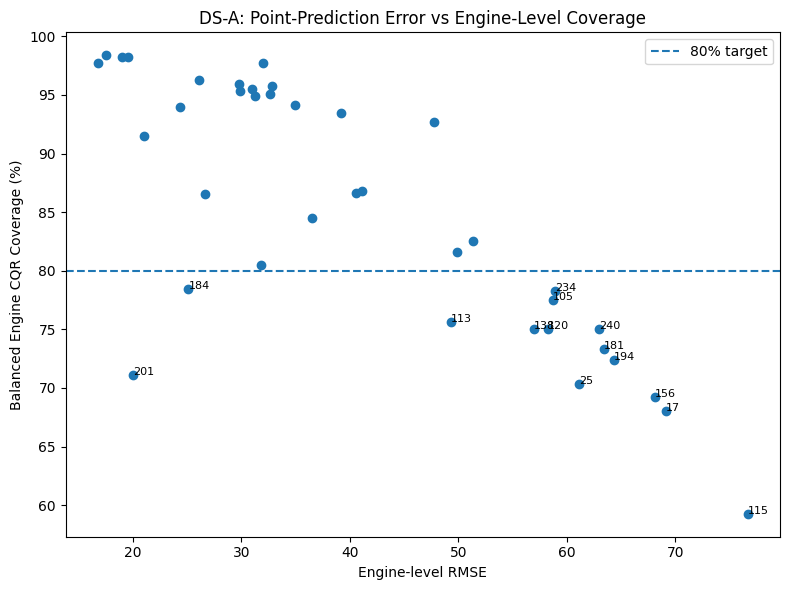

In [39]:
plt.figure(figsize=(8, 6))

plt.scatter(
    engine_results["RMSE"],
    engine_results["Balanced_Coverage"]
)

plt.axhline(
    80,
    linestyle="--",
    label="80% target"
)

for _, row in problem_engines.iterrows():
    plt.annotate(
        str(int(row["engine_id"])),
        (
            row["RMSE"],
            row["Balanced_Coverage"]
        ),
        fontsize=8
    )

plt.xlabel("Engine-level RMSE")
plt.ylabel("Balanced Engine CQR Coverage (%)")

plt.title(
    "DS-A: Point-Prediction Error vs Engine-Level Coverage"
)

plt.legend()
plt.tight_layout()
plt.show()

In [40]:
# ============================================================
# DS-A LIFE-STAGE RELIABILITY
# ============================================================

def assign_life_stage(rul):
    if rul > 80:
        return "Early"
    elif rul > 40:
        return "Mid"
    else:
        return "Late"


life_stage = np.array([
    assign_life_stage(r)
    for r in y_test_ds
])


stage_results = []

for stage in ["Early", "Mid", "Late"]:

    mask = life_stage == stage

    if np.sum(mask) == 0:
        continue

    stage_rmse = np.sqrt(
        mean_squared_error(
            y_test_ds[mask],
            p50_test[mask]
        )
    )

    stage_mae = mean_absolute_error(
        y_test_ds[mask],
        p50_test[mask]
    )

    asym_cov = (
        100 * np.mean(
            asym_covered[mask]
        )
    )

    balanced_cov = (
        100 * np.mean(
            balanced_covered[mask]
        )
    )

    asym_width = np.mean(
        asym_upper[mask] -
        asym_lower[mask]
    )

    balanced_width = np.mean(
        balanced_upper[mask] -
        balanced_lower[mask]
    )

    stage_results.append({
        "Life_Stage": stage,
        "N_Windows": int(np.sum(mask)),
        "RMSE": stage_rmse,
        "MAE": stage_mae,
        "Asym_Coverage": asym_cov,
        "Balanced_Coverage": balanced_cov,
        "Asym_Width": asym_width,
        "Balanced_Width": balanced_width
    })


stage_results = pd.DataFrame(
    stage_results
)

display(
    stage_results.round(3)
)


,Life_Stage,N_Windows,RMSE,MAE,Asym_Coverage,Balanced_Coverage,Asym_Width,Balanced_Width
0,Early,1254,13.436,11.672,73.764,95.614,89.762001,97.073997
1,Mid,388,48.156,44.875,94.845,95.876,84.331001,91.643997
2,Late,401,69.349,63.186,45.137,54.364,71.605003,78.917000


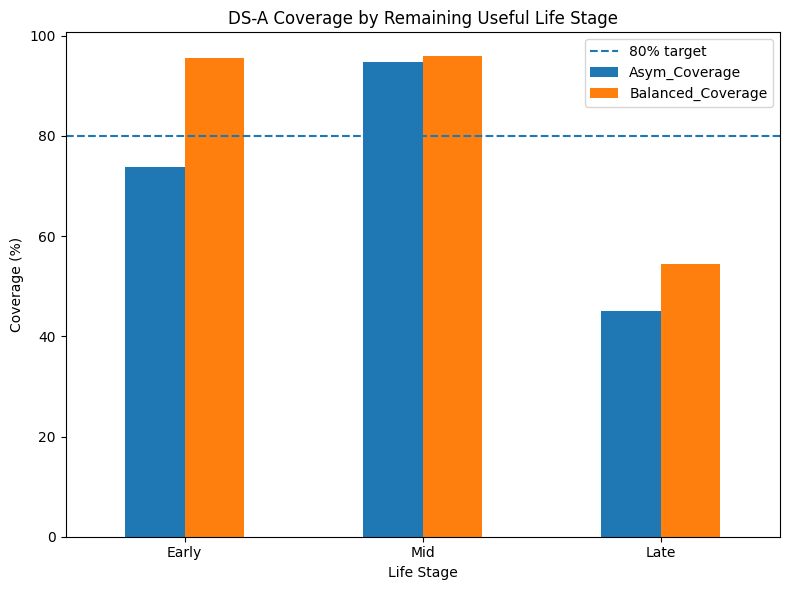

In [41]:
plot_stage = stage_results.set_index(
    "Life_Stage"
)[
    [
        "Asym_Coverage",
        "Balanced_Coverage"
    ]
]

ax = plot_stage.plot(
    kind="bar",
    figsize=(8, 6)
)

ax.axhline(
    80,
    linestyle="--",
    label="80% target"
)

ax.set_ylabel(
    "Coverage (%)"
)

ax.set_xlabel(
    "Life Stage"
)

ax.set_title(
    "DS-A Coverage by Remaining Useful Life Stage"
)

plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()


In [42]:
problem_ids = set(
    problem_engines["engine_id"]
)

problem_mask = np.array([
    eng in problem_ids
    for eng in ids_test
])

problem_stage_summary = []

for stage in ["Early", "Mid", "Late"]:

    mask = (
        problem_mask &
        (life_stage == stage)
    )

    if np.sum(mask) == 0:
        continue

    problem_stage_summary.append({
        "Life_Stage": stage,
        "N_Windows": int(np.sum(mask)),

        "RMSE": np.sqrt(
            mean_squared_error(
                y_test_ds[mask],
                p50_test[mask]
            )
        ),

        "Balanced_Coverage":
            100 * np.mean(
                balanced_covered[mask]
            )
    })


problem_stage_summary = pd.DataFrame(
    problem_stage_summary
)

display(
    problem_stage_summary.round(3)
)


,Life_Stage,N_Windows,RMSE,Balanced_Coverage
0,Early,270,17.316,89.630
1,Mid,145,51.628,91.724
2,Late,150,87.371,27.333


## DS-A with a trajectory diagnostic

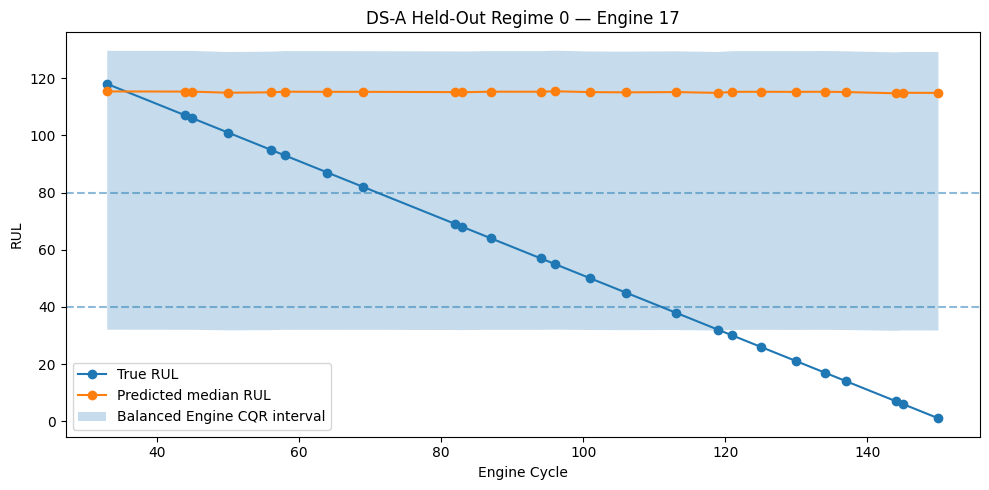

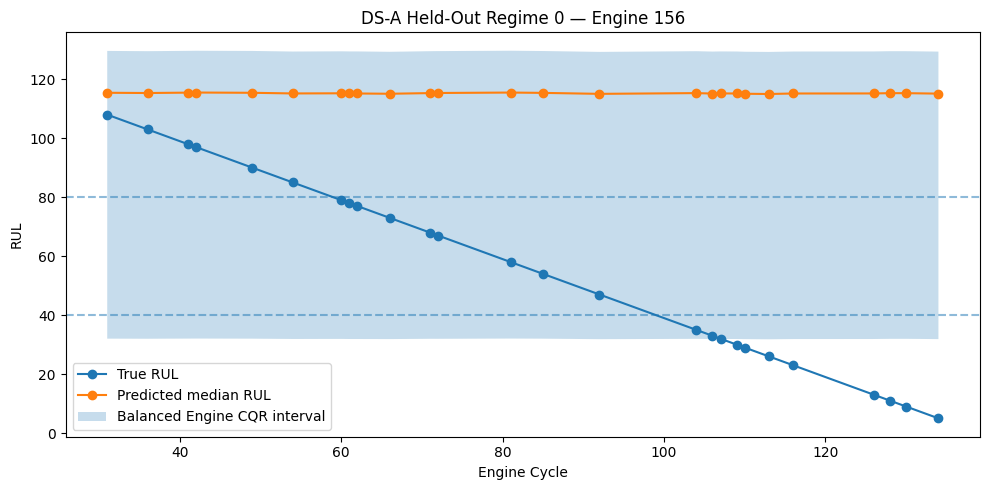

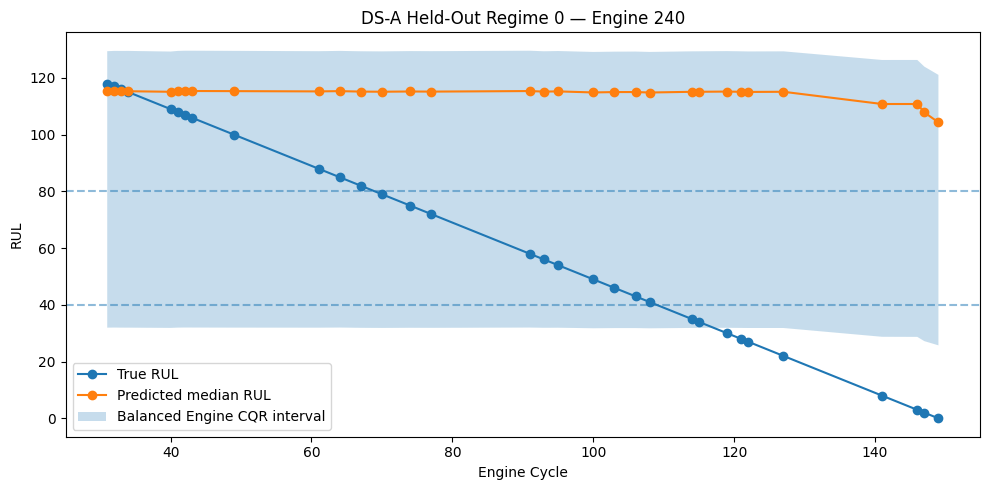

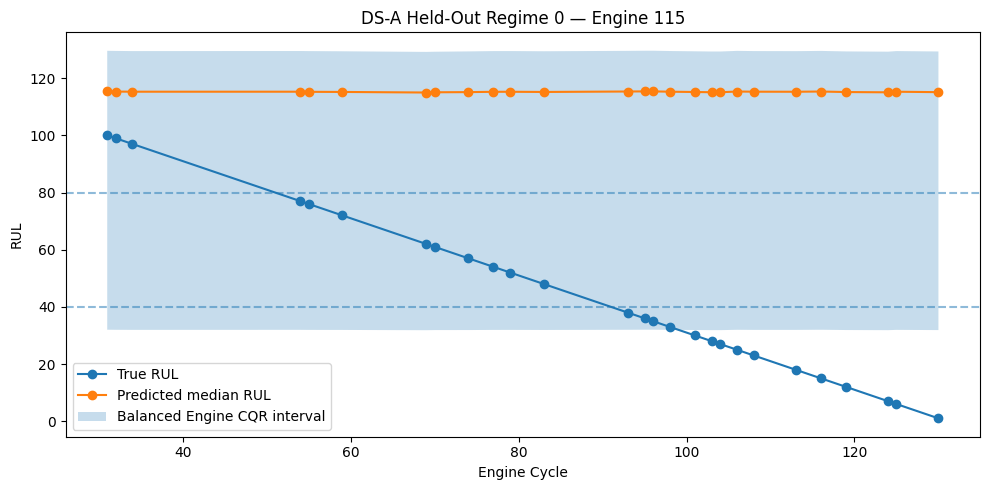

In [43]:
# ============================================================
# DS-A TRAJECTORY DIAGNOSTIC
# Worst-covered engines
# ============================================================

worst_engines = [17, 156, 240, 115]

for eng in worst_engines:

    mask = ids_test == eng

    order = np.argsort(cycles_test[mask])

    cycles_eng = cycles_test[mask][order]
    y_eng = y_test_ds[mask][order]

    pred_eng = p50_test[mask][order]

    lower_eng = balanced_lower[mask][order]
    upper_eng = balanced_upper[mask][order]

    plt.figure(figsize=(10, 5))

    plt.plot(
        cycles_eng,
        y_eng,
        marker="o",
        label="True RUL"
    )

    plt.plot(
        cycles_eng,
        pred_eng,
        marker="o",
        label="Predicted median RUL"
    )

    plt.fill_between(
        cycles_eng,
        lower_eng,
        upper_eng,
        alpha=0.25,
        label="Balanced Engine CQR interval"
    )

    plt.axhline(
        80,
        linestyle="--",
        alpha=0.5
    )

    plt.axhline(
        40,
        linestyle="--",
        alpha=0.5
    )

    plt.xlabel("Engine Cycle")
    plt.ylabel("RUL")

    plt.title(
        f"DS-A Held-Out Regime 0 — Engine {eng}"
    )

    plt.legend()
    plt.tight_layout()
    plt.show()



In [44]:
final_ds_a = pd.DataFrame([
    {
        "Metric": "Point RMSE",
        "Value": test_rmse
    },
    {
        "Metric": "Point MAE",
        "Value": test_mae
    },
    {
        "Metric": "Asymmetric CQR Coverage (%)",
        "Value": asym_picp
    },
    {
        "Metric": "Asymmetric Mean Width",
        "Value": asym_mpiw
    },
    {
        "Metric": "Balanced CQR Coverage (%)",
        "Value": balanced_picp
    },
    {
        "Metric": "Balanced Mean Width",
        "Value": balanced_mpiw
    },
    {
        "Metric": "Balanced engines >= 80%",
        "Value": np.sum(
            engine_results["Balanced_Coverage"] >= 80
        )
    },
    {
        "Metric": "Balanced worst-engine coverage (%)",
        "Value": engine_results[
            "Balanced_Coverage"
        ].min()
    },
    {
        "Metric": "Mid-life Balanced coverage (%)",
        "Value": stage_results.loc[
            stage_results["Life_Stage"] == "Mid",
            "Balanced_Coverage"
        ].iloc[0]
    },
    {
        "Metric": "Problem-engine mid-life coverage (%)",
        "Value": problem_stage_summary.loc[
            problem_stage_summary["Life_Stage"] == "Mid",
            "Balanced_Coverage"
        ].iloc[0]
    }
])

display(final_ds_a.round(3))

,Metric,Value
0,Point RMSE,38.668
1,Point MAE,28.089
2,Asymmetric CQR Coverage (%),72.149
3,Asymmetric Mean Width,85.166
4,Balanced CQR Coverage (%),87.567
5,Balanced Mean Width,92.479
6,Balanced engines >= 80%,24.000
7,Balanced worst-engine coverage (%),59.259
8,Mid-life Balanced coverage (%),95.876
9,Problem-engine mid-life coverage (%),91.724



---

# Paper 1 fixed-spec five-seed UQ confirmation

**Purpose:** confirm stochastic stability of the already-frozen Paper 1 uncertainty results.

**Seeds:** 42, 123, 456, 789, 1000.

**Frozen choices:** no architecture selection, no hyperparameter tuning, no split changes, no calibration-rule changes, no DS-A/DS-B threshold changes. The final quantile model uses 25 epochs, batch size 64, Adam 1e-3, the 20→18 linear projection, BiLSTM(64 each direction), temporal attention, and q10/q50/q90 pinball loss.

**Methods reported:** Asymmetric CQR and Balanced Engine CQR.

**Metrics:** PICP, MPIW, Winkler score, point RMSE/MAE, calibration corrections. Outputs are written per seed and as mean ± sample SD.

**Quantile convention preserved from the frozen notebooks:** finite-sample conformal quantiles use `method="higher"`. The first-stage within-engine 0.80 quantile in Balanced Engine CQR intentionally uses NumPy's default interpolation, matching the frozen implementation; the second-stage across-engine conformal quantile uses `method="higher"`.

Seed 42 is treated as a reproducibility check against the frozen master result. A mismatch is a warning to stop and resolve the runtime/data specification before using the multi-seed summary.


## DS-A confirmatory section
Run the original notebook through preprocessing/window construction so the frozen `X_train_ds`, `y_train_ds`, `X_cal_ds`, `y_cal_ds`, `ids_cal`, `X_test_ds`, and `y_test_ds` arrays exist. Then run the cells below. The confirmatory loop builds fresh models for all five seeds; it does not use the original seed-42 trained model.

In [20]:

import os, random, time, gc
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dense, Layer
from tensorflow.keras.models import Model

SEEDS = [42, 123, 456, 789, 1000]
ALPHA = 0.20
QUANTILES = [0.10, 0.50, 0.90]
EPOCHS = 25
BATCH_SIZE = 256

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

def conformal_quantile(scores, alpha):
    scores = np.asarray(scores)
    n = len(scores)
    q_level = min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)
    return float(np.quantile(scores, q_level, method="higher"))

def interval_metrics(y, lo, hi, alpha=ALPHA):
    y = np.asarray(y)
    lo = np.asarray(lo)
    hi = np.asarray(hi)
    covered = (y >= lo) & (y <= hi)
    width = hi - lo
    winkler = (
        width
        + (2.0 / alpha) * (lo - y) * (y < lo)
        + (2.0 / alpha) * (y - hi) * (y > hi)
    )
    return {
        "PICP": 100.0 * covered.mean(),
        "MPIW": width.mean(),
        "Winkler": winkler.mean(),
    }

def summarize_seed_table(df):
    numeric_cols = [
        c for c in df.columns
        if c not in ("Condition", "Method", "Seed")
        and pd.api.types.is_numeric_dtype(df[c])
    ]
    rows = []
    for (condition, method), g in df.groupby(["Condition","Method"], sort=False):
        row = {"Condition": condition, "Method": method, "N_Seeds": len(g)}
        for c in numeric_cols:
            row[c + "_mean"] = g[c].mean()
            row[c + "_sd"] = g[c].std(ddof=1)
        rows.append(row)
    return pd.DataFrame(rows)

def out_dir():
    drive_dir = "/content/drive/MyDrive/FD004_Research/Paper1_MultiSeed_UQ"
    if os.path.isdir("/content/drive/MyDrive"):
        os.makedirs(drive_dir, exist_ok=True)
        return drive_dir
    local = "/content/Paper1_MultiSeed_UQ"
    os.makedirs(local, exist_ok=True)
    return local

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Output directory:", out_dir())


TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Output directory: /content/drive/MyDrive/FD004_Research/Paper1_MultiSeed_UQ


In [21]:

required = ["X_train_ds","y_train_ds","X_cal_ds","y_cal_ds","ids_cal","X_test_ds","y_test_ds"]
missing = [v for v in required if v not in globals()]
if missing:
    raise RuntimeError(
        "Missing frozen preprocessed arrays: " + ", ".join(missing) +
        "\nRun the original notebook through data preparation/window construction first."
    )
assert X_train_ds.shape[-1] == 20
assert X_cal_ds.shape[-1] == 20
assert X_test_ds.shape[-1] == 20
print("Train:", X_train_ds.shape, "Cal:", X_cal_ds.shape, "Test:", X_test_ds.shape)
print("Calibration engines:", len(np.unique(ids_cal)))


Train: (28322, 30, 20) Cal: (6021, 30, 20) Test: (2043, 30, 20)
Calibration engines: 37


In [22]:

class ConfirmatoryAttention(Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
    def build(self, input_shape):
        dim = input_shape[-1]
        self.W = self.add_weight(name="W", shape=(dim, dim), initializer="glorot_uniform", trainable=True)
        self.b = self.add_weight(name="b", shape=(dim,), initializer="zeros", trainable=True)
        self.v = self.add_weight(name="v", shape=(dim, 1), initializer="glorot_uniform", trainable=True)
        super().build(input_shape)
    def call(self, inputs):
        e = tf.nn.tanh(tf.tensordot(inputs, self.W, axes=1) + self.b)
        scores = tf.tensordot(e, self.v, axes=1)
        weights = tf.nn.softmax(scores, axis=1)
        return tf.reduce_sum(inputs * weights, axis=1)

def tilted_loss_confirm(q, y_true, y_pred):
    error = y_true - y_pred
    return tf.maximum(q * error, (q - 1.0) * error)

def loss_confirm(y_true, y_pred):
    y_true = tf.cast(tf.reshape(y_true, (-1,1)), tf.float32)
    return tf.reduce_mean(tf.add_n([
        tilted_loss_confirm(q, y_true, y_pred[:,i:i+1])
        for i,q in enumerate(QUANTILES)
    ]))

def build_confirmatory_model():
    inputs = Input(shape=(30,20), name="input_window")
    projection = Dense(18, use_bias=False, name="projection")(inputs)
    lstm_output = Bidirectional(LSTM(64, return_sequences=True), name="bilstm")(projection)
    context = ConfirmatoryAttention(name="temporal_attention")(lstm_output)
    outputs = Dense(3, activation="linear", name="quantiles")(context)
    model = Model(inputs, outputs, name="Paper1_FiveSeed_Confirmatory")
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=loss_confirm)
    return model


In [23]:

CONDITION = "DS-A"
records = []
for run_i, seed in enumerate(SEEDS,1):
    print(f"\n[{run_i}/{len(SEEDS)}] {CONDITION} seed {seed}")
    tf.keras.backend.clear_session()
    gc.collect()
    set_seed(seed)
    model_ms = build_confirmatory_model()
    model_ms.fit(
        X_train_ds, y_train_ds,
        epochs=EPOCHS, batch_size=BATCH_SIZE,
        verbose=2, shuffle=True
    )

    cal_pred = model_ms.predict(X_cal_ds, batch_size=512, verbose=0)
    test_pred = model_ms.predict(X_test_ds, batch_size=512, verbose=0)
    p10c,p50c,p90c = cal_pred[:,0],cal_pred[:,1],cal_pred[:,2]
    p10,p50,p90 = test_pred[:,0],test_pred[:,1],test_pred[:,2]

    # Frozen Asymmetric CQR.
    q_lo = conformal_quantile(p10c - y_cal_ds, ALPHA/2)
    q_hi = conformal_quantile(y_cal_ds - p90c, ALPHA/2)
    lo_a = np.maximum(0.0, p10 - q_lo)
    hi_a = np.maximum(0.0, p90 + q_hi)

    # Frozen Balanced Engine CQR.
    cal_err = np.maximum(p10c - y_cal_ds, y_cal_ds - p90c)
    cal_engines_local = np.unique(ids_cal)
    eng_q80 = np.asarray([
        np.quantile(cal_err[ids_cal == eng], 0.80)
        for eng in cal_engines_local
    ])
    n_eng = len(cal_engines_local)
    q_level_eng = min(1.0, np.ceil((n_eng + 1) * (1 - ALPHA)) / n_eng)
    q_bal = float(np.quantile(eng_q80, q_level_eng, method="higher"))
    lo_b = np.maximum(0.0, p10 - q_bal)
    hi_b = np.maximum(0.0, p90 + q_bal)

    rmse = float(np.sqrt(mean_squared_error(y_test_ds, p50)))
    mae = float(mean_absolute_error(y_test_ds, p50))

    for method,lo,hi,qa,qb in [
        ("Asymmetric CQR",lo_a,hi_a,q_lo,q_hi),
        ("Balanced Engine CQR",lo_b,hi_b,q_bal,q_bal)
    ]:
        met = interval_metrics(y_test_ds, lo, hi)
        records.append({
            "Condition":CONDITION,"Seed":seed,"Method":method,
            "PICP":met["PICP"],"MPIW":met["MPIW"],"Winkler":met["Winkler"],
            "RMSE":rmse,"MAE":mae,"Q_lower":qa,"Q_upper":qb
        })
    print(pd.DataFrame(records[-2:])[["Seed","Method","PICP","MPIW","Winkler","RMSE"]].round(3).to_string(index=False))

seed_df = pd.DataFrame(records)
summary_df = summarize_seed_table(seed_df)

od = out_dir()
slug = CONDITION.replace("-","_")
seed_df.to_csv(os.path.join(od, f"Paper1_FiveSeed_{slug}_per_seed.csv"), index=False)
summary_df.to_csv(os.path.join(od, f"Paper1_FiveSeed_{slug}_summary.csv"), index=False)
display(seed_df.round(3))
display(summary_df.round(3))
print("Saved outputs to", od)



[1/5] DS-A seed 42
Epoch 1/25
111/111 - 6s - 52ms/step - loss: 114.8550
Epoch 2/25
111/111 - 1s - 10ms/step - loss: 91.3946
Epoch 3/25
111/111 - 1s - 10ms/step - loss: 76.5766
Epoch 4/25
111/111 - 1s - 9ms/step - loss: 64.7461
Epoch 5/25
111/111 - 2s - 16ms/step - loss: 55.1087
Epoch 6/25
111/111 - 2s - 21ms/step - loss: 47.2368
Epoch 7/25
111/111 - 1s - 9ms/step - loss: 40.8947
Epoch 8/25
111/111 - 1s - 9ms/step - loss: 35.7775
Epoch 9/25
111/111 - 1s - 9ms/step - loss: 31.7280
Epoch 10/25
111/111 - 1s - 10ms/step - loss: 29.2791
Epoch 11/25
111/111 - 2s - 14ms/step - loss: 29.0245
Epoch 12/25
111/111 - 1s - 10ms/step - loss: 28.9571
Epoch 13/25
111/111 - 1s - 9ms/step - loss: 28.9148
Epoch 14/25
111/111 - 1s - 9ms/step - loss: 28.8926
Epoch 15/25
111/111 - 1s - 13ms/step - loss: 28.8712
Epoch 16/25
111/111 - 2s - 14ms/step - loss: 28.8845
Epoch 17/25
111/111 - 2s - 14ms/step - loss: 28.8650
Epoch 18/25
111/111 - 1s - 10ms/step - loss: 28.6278
Epoch 19/25
111/111 - 1s - 10ms/step - l

,Condition,Seed,Method,PICP,MPIW,Winkler,RMSE,MAE,Q_lower,Q_upper
0,DS-A,42,Asymmetric CQR,72.149,85.166000,102.143997,38.668,28.089,1.169,-0.302
1,DS-A,42,Balanced Engine CQR,87.567,92.478996,104.639999,38.668,28.089,4.090,4.090
2,DS-A,123,Asymmetric CQR,73.764,46.320999,78.674004,24.642,16.047,-2.235,7.479
3,DS-A,123,Balanced Engine CQR,92.168,75.503998,85.424004,24.642,16.047,18.207,18.207
4,DS-A,456,Asymmetric CQR,72.002,56.355999,92.135002,29.207,18.874,0.425,0.055
5,DS-A,456,Balanced Engine CQR,88.595,77.570000,93.985001,29.207,18.874,11.154,11.154
6,DS-A,789,Asymmetric CQR,72.149,90.223999,123.290001,40.098,30.965,0.477,-0.572
7,DS-A,789,Balanced Engine CQR,80.323,98.944000,121.875000,40.098,30.965,4.313,4.313
8,DS-A,1000,Asymmetric CQR,71.366,50.634998,90.328003,25.745,17.209,0.135,4.523
9,DS-A,1000,Balanced Engine CQR,87.812,76.031998,91.332001,25.745,17.209,15.535,15.535


,Condition,Method,N_Seeds,PICP_mean,PICP_sd,MPIW_mean,MPIW_sd,Winkler_mean,Winkler_sd,RMSE_mean,RMSE_sd,MAE_mean,MAE_sd,Q_lower_mean,Q_lower_sd,Q_upper_mean,Q_upper_sd
0,DS-A,Asymmetric CQR,5,72.286,0.887,65.739998,20.434,97.314003,16.742,31.672,7.255,22.237,6.807,-0.006,1.302,2.237,3.599
1,DS-A,Balanced Engine CQR,5,87.293,4.312,84.106003,10.865,99.450996,14.338,31.672,7.255,22.237,6.807,10.660,6.411,10.660,6.411


Saved outputs to /content/drive/MyDrive/FD004_Research/Paper1_MultiSeed_UQ


In [24]:

# Seed-42 reproduction gate against frozen Paper 1 master.
expected_rmse = 24.869
expected = {'rmse': 24.869, 'Asymmetric CQR': {'PICP': 73.13, 'MPIW': 45.003}, 'Balanced Engine CQR': {'PICP': 90.21, 'MPIW': 66.737}}
tols = {"RMSE":0.75,"PICP":0.75,"MPIW":1.50}

s42 = seed_df[seed_df["Seed"] == 42].set_index("Method")
rows = []
for method in ["Asymmetric CQR","Balanced Engine CQR"]:
    row = {"Method":method}
    rmse_obs = float(s42.loc[method,"RMSE"])
    row["RMSE_observed"] = rmse_obs
    row["RMSE_expected"] = expected_rmse
    row["RMSE_PASS"] = abs(rmse_obs-expected_rmse) <= tols["RMSE"]
    ok = row["RMSE_PASS"]
    for metric in ["PICP","MPIW"]:
        obs = float(s42.loc[method,metric])
        exp = expected[method][metric]
        passed = abs(obs-exp) <= tols[metric]
        row[metric+"_observed"] = obs
        row[metric+"_expected"] = exp
        row[metric+"_PASS"] = passed
        ok &= passed
    row["Overall_PASS"] = ok
    rows.append(row)

gate = pd.DataFrame(rows)
display(gate)
gate.to_csv(os.path.join(out_dir(), f"Paper1_FiveSeed_DS_A_seed42_gate.csv"), index=False)
if not bool(gate["Overall_PASS"].all()):
    print("STOP: seed-42 reproduction gate failed. Do not use this multi-seed summary until the frozen runtime specification is reconciled.")
else:
    print("PASS: seed-42 reproduction gate passed.")


,Method,RMSE_observed,RMSE_expected,RMSE_PASS,PICP_observed,PICP_expected,PICP_PASS,MPIW_observed,MPIW_expected,MPIW_PASS,Overall_PASS
0,Asymmetric CQR,38.667689,24.869,False,72.148801,73.13,False,85.166389,45.003,False,False
1,Balanced Engine CQR,38.667689,24.869,False,87.567303,90.21,False,92.478798,66.737,False,False


STOP: seed-42 reproduction gate failed. Do not use this multi-seed summary until the frozen runtime specification is reconciled.
